# Customer Segmentation using K-Means

## Objective

Group customers into Low, Regular and High Value customers using K-Means clustering.

In [1]:
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("../data/processed/processed_superstore.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Order Weekday,Shipping Days,Profit Margin (%),Sales Per Unit,Discount Category,Order Size,Sales Category,Profit Category,Shipping Speed,Customer Lifetime Value
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,3,16.00,130.98,No Discount,Small,Medium Sales,Low Profit,Standard,1148.7800
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,3,30.00,243.98,No Discount,Medium,High Sales,Medium Profit,Standard,1148.7800
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Sunday,4,47.00,7.31,No Discount,Small,Low Sales,Low Profit,Standard,1119.4830
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,7,-40.00,191.52,Medium,Medium,High Sales,Loss,Slow,2602.5755
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,7,11.25,11.18,Low,Small,Low Sales,Low Profit,Slow,2602.5755


In [3]:
customer = (
    df.groupby("Customer ID")
      .agg({
          "Sales":"sum",
          "Profit":"sum",
          "Order ID":"nunique"
      })
      .reset_index()
)

customer.head()

,Customer ID,Sales,Profit,Order ID
0,AA-10315,5563.560,-362.8825,5
1,AA-10375,1056.390,277.3824,9
2,AA-10480,1790.512,435.8274,4
3,AA-10645,5086.935,857.8033,6
4,AB-10015,886.156,129.3465,3


In [4]:
X = customer[["Sales","Profit","Order ID"]]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

customer["Cluster"] = kmeans.fit_predict(X_scaled)

In [7]:
customer.groupby("Cluster")[["Sales", "Profit", "Order ID"]].mean()

,Sales,Profit,Order ID
Cluster,,,
0,3461.219371,368.912188,8.342593
1,1519.240849,88.539357,4.434146
2,9370.797219,2213.022653,8.271186


In [8]:
cluster_rank = (
    customer.groupby("Cluster")["Sales"]
    .mean()
    .sort_values()
)

mapping = {
    cluster_rank.index[0]:"Low Value",
    cluster_rank.index[1]:"Regular",
    cluster_rank.index[2]:"High Value"
}

customer["Segment"] = customer["Cluster"].map(mapping)

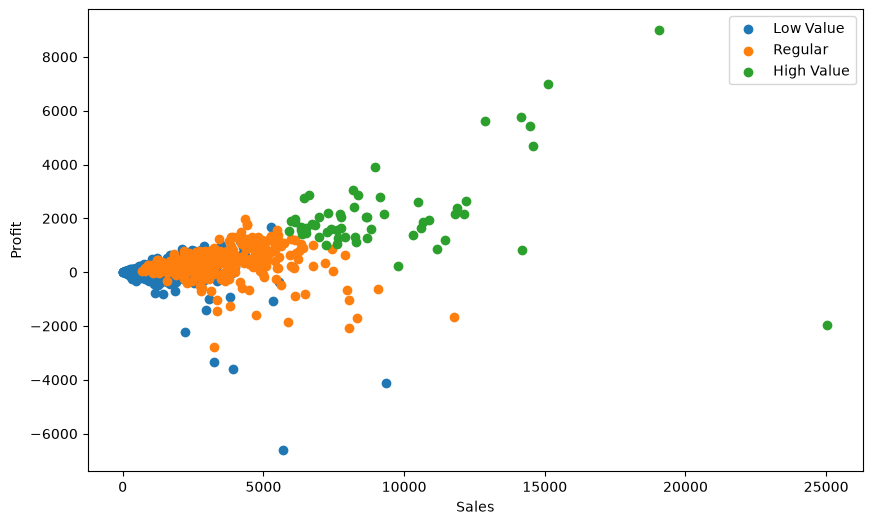

In [9]:
plt.figure(figsize=(10,6))

for segment in customer["Segment"].unique():
    temp = customer[
        customer["Segment"]==segment
    ]

    plt.scatter(
        temp["Sales"],
        temp["Profit"],
        label=segment
    )

plt.xlabel("Sales")

plt.ylabel("Profit")

plt.legend()

plt.show()

In [10]:
customer.groupby("Segment").agg({
    "Sales":"mean",
    "Profit":"mean",
    "Order ID":"mean"
})

,Sales,Profit,Order ID
Segment,,,
High Value,9370.797219,2213.022653,8.271186
Low Value,1519.240849,88.539357,4.434146
Regular,3461.219371,368.912188,8.342593


In [11]:
cluster_summary = (
    customer.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Sales=("Sales", "mean"),
        Avg_Profit=("Profit", "mean"),
        Avg_Orders=("Order ID", "mean"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

cluster_summary

,Customers,Avg_Sales,Avg_Profit,Avg_Orders,Total_Sales,Total_Profit
Cluster,,,,,,
0,324,3461.219371,368.912188,8.342593,1.121435e+06,119527.5488
1,410,1519.240849,88.539357,4.434146,6.228887e+05,36301.1364
2,59,9370.797219,2213.022653,8.271186,5.528770e+05,130568.3365


## Conclusion

• High Value customers generate maximum sales and profit.

• Regular customers contribute consistent revenue.

• Low Value customers have fewer orders and lower sales.

• These segments can be targeted with different marketing strategies.